# Khánh · Dữ liệu Kvasir-SEG

Xem phân bố của các split, đối chiếu audit và chạy Dataset/DataLoader để quan sát ảnh RGB, mask và augmentation trên các mẫu train thật.

Notebook đã lưu sẵn bảng và hình. Để chạy lại, chọn kernel Python của đồ án trong VS Code hoặc Jupyter rồi bấm **Run All**. Môi trường dùng các gói trong [requirements.txt](../../../requirements.txt) và [requirements-notebook.txt](../../../requirements-notebook.txt).

In [1]:
from pathlib import Path
import json
import sys

cwd = Path.cwd().resolve()
candidates = (cwd, *cwd.parents, cwd / "unet-vs-unetplusplus-polyp")
root = next(
    (folder for folder in candidates if (folder / "project.py").is_file()
     and (folder / "configs" / "protocol_lock.json").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Mở notebook từ thư mục đồ án hoặc thư mục members/<tên>/works_done.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
colors = {"A": "#345e86", "B": "#b76b21", "C": "#187c70"}

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

## Manifest cố định và nhóm diện tích mask

[prepare_data_splits.py](prepare_data_splits.py) tạo metadata và chia phân tầng theo diện tích mask. Các thí nghiệm A/B/C sử dụng cột `split` trong [dataset_splits.csv](dataset_splits.csv), với 700 train, 150 validation và 150 test. Cột `kfold_5` lưu phương án chia fold riêng. Nhóm small/medium/large phản ánh phần diện tích ảnh được mask phủ.

In [2]:
from members.khanh.works_done.dataset import (
    DEFAULT_MANIFEST, KvasirDataset, get_dataloader, validate_manifest,
)

manifest = pd.read_csv(DEFAULT_MANIFEST)
validate_manifest(manifest)
split_order = ["train", "val", "test"]
size_order = ["small", "medium", "large"]
split_counts = pd.crosstab(manifest["split"], manifest["polyp_category"]).loc[split_order, size_order]
split_table = split_counts.assign(Tổng=split_counts.sum(axis=1))
split_table.loc["Tổng"] = split_table.sum()
display(split_table.rename_axis(index="Split", columns="Nhóm diện tích"))

Nhóm diện tích,small,medium,large,Tổng
Split,,,,
train,140,374,186,700
val,30,80,40,150
test,30,80,40,150
Tổng,200,534,266,1000


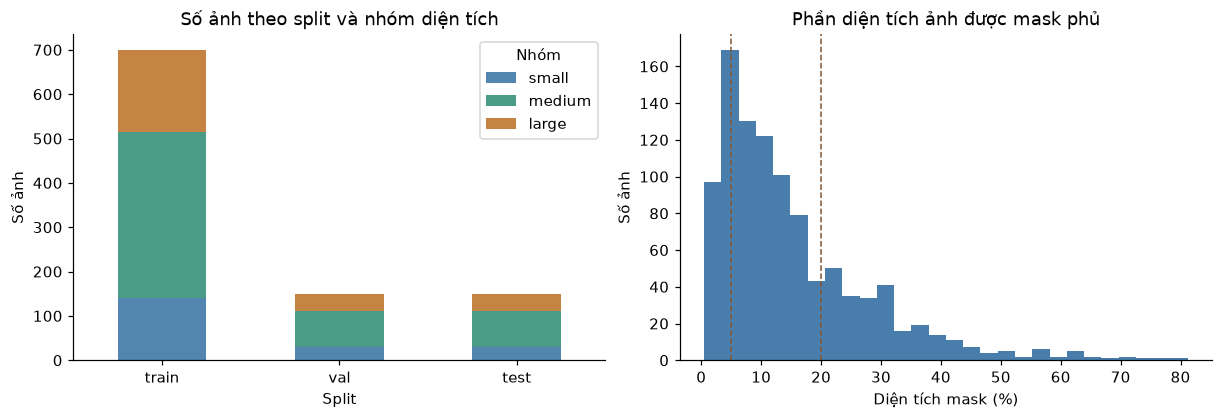

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
size_colors = ["#5286b1", "#4a9c88", "#c68443"]
split_counts.plot.bar(stacked=True, color=size_colors, rot=0, ax=axes[0])
axes[0].set(title="Số ảnh theo split và nhóm diện tích", xlabel="Split", ylabel="Số ảnh")
axes[0].legend(title="Nhóm")
axes[1].hist(100 * manifest["polyp_area_ratio"], bins=28, color="#487dac")
for cutoff in (5, 20):
    axes[1].axvline(cutoff, color="#875630", ls="--", lw=1)
axes[1].set(title="Phần diện tích ảnh được mask phủ", xlabel="Diện tích mask (%)", ylabel="Số ảnh")
plt.show()

## Kết quả audit đã lưu

[audit_data.py](audit_data.py) đối chiếu ID, kích thước, metadata và phát hiện ảnh trùng khớp pixel sau giải mã. SHA-256 cho biết audit và notebook đang dùng cùng bản manifest. Audit hiện có chỉ kiểm tra trùng chính xác theo ảnh, phạm vi theo bệnh nhân hoặc video chưa được xác minh.

In [4]:
from hashlib import sha256

audit = read_json(root / "results/data_audit/audit.json")
display(pd.DataFrame([{
    "Trạng thái audit": audit["status"],
    "Cặp ảnh-mask": audit["pairs"],
    "Mask rỗng": audit["empty_masks"],
    "Nhóm trùng chính xác": len(audit["exact_duplicate_groups"]),
    "Vấn đề": len(audit["issues"]),
    "Khớp SHA-256 manifest": sha256(DEFAULT_MANIFEST.read_bytes()).hexdigest() == audit["manifest_sha256"],
}]))

,Trạng thái audit,Cặp ảnh-mask,Mask rỗng,Nhóm trùng chính xác,Vấn đề,Khớp SHA-256 manifest
0,passed,1000,0,0,0,True


## Batch thật và augmentation

[dataset.py](dataset.py) đọc ảnh RGB, đưa giá trị về [0, 1] và chuyển mask grayscale có giá trị lớn hơn 127 thành foreground. Resize mask dùng nearest-neighbor. Train dùng biến đổi hình học đồng bộ trên ảnh và mask, còn ColorJitter áp dụng cho ảnh. Validation và test dùng tiền xử lý cố định.

In [5]:
import torch

batch_loader = get_dataloader("train", batch_size=4, num_workers=0, return_id=True)
images, masks, ids = next(iter(batch_loader))
print(f"Ảnh (N,C,H,W): {tuple(images.shape)}, {images.dtype}")
print(f"Mask (N,C,H,W): {tuple(masks.shape)}, {masks.dtype}")
print(f"Giá trị mask: {masks.unique().tolist()}")
display(pd.DataFrame({"ID": list(ids), "Tỷ lệ foreground (%)": (100 * masks.mean((1, 2, 3))).tolist()}).round(2))

Ảnh (N,C,H,W): (4, 3, 256, 256), torch.float32
Mask (N,C,H,W): (4, 1, 256, 256), torch.float32
Giá trị mask: [0.0, 1.0]


,ID,Tỷ lệ foreground (%)
0,cju8chxndsre008015uisl4si,3.59
1,cju16ach3m1da0993r1dq3sn2,30.96
2,cju3yb47cj1xq0817zfotbni4,13.68
3,cju5huurrecm70801y680y13m,10.74


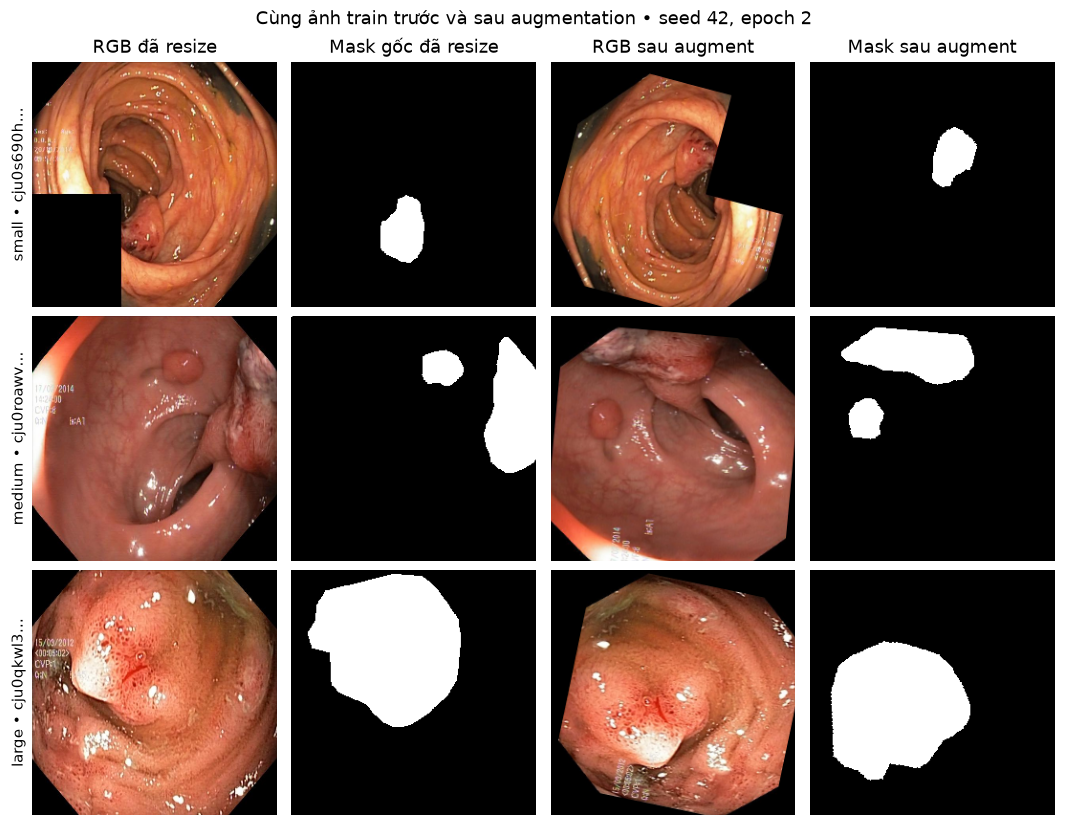

In [6]:
EPOCH = 2
plain = KvasirDataset(split="train", seed=42, return_id=True, augment=False)
augmented = KvasirDataset(split="train", seed=42, return_id=True)
augmented.set_epoch(EPOCH)
sample_indices = [
    (plain.df["polyp_category"] == size).idxmax() for size in size_order
]
fig, axes = plt.subplots(3, 4, figsize=(9.6, 7.4), layout="constrained")
for index, size, row_axes in zip(sample_indices, size_order, axes):
    image, mask, image_id = plain[index]
    aug_image, aug_mask, aug_id = augmented[index]
    assert image_id == aug_id
    row_axes[0].set_ylabel(f"{size} • {image_id[:9]}…")
    for ax, tensor in zip(row_axes, (image, mask, aug_image, aug_mask)):
        if tensor.shape[0] == 1:
            ax.imshow(tensor[0].numpy(), cmap="gray", vmin=0, vmax=1)
        else:
            ax.imshow(tensor.permute(1, 2, 0).numpy())
        ax.set(xticks=[], yticks=[])
        for spine in ax.spines.values():
            spine.set_visible(False)
for ax, title in zip(axes[0], ("RGB đã resize", "Mask gốc đã resize", "RGB sau augment", "Mask sau augment")):
    ax.set_title(title)
fig.suptitle(f"Cùng ảnh train trước và sau augmentation • seed 42, epoch {EPOCH}")
plt.show()

In [7]:
augmented.set_epoch(EPOCH)
image1, mask1, _ = augmented[sample_indices[0]]
augmented.set_epoch(EPOCH)
image2, mask2, _ = augmented[sample_indices[0]]
print(f"Cùng seed, epoch và thứ tự đọc: RGB giống nhau = {torch.equal(image1, image2)}, "
      f"mask giống nhau = {torch.equal(mask1, mask2)}")

Cùng seed, epoch và thứ tự đọc: RGB giống nhau = True, mask giống nhau = True


Đổi `EPOCH` và chạy lại hai ô cuối để xem một chuỗi augmentation khác. Mỗi hàng giữ cùng ID để nhìn sự dịch chuyển của ảnh và mask.